# Energy Consumption Management Using Q-Learning and SARSA
## Final corrected and reproducible case study

**Dataset:** Household Electric Power Consumption (minute-level records)  
**Algorithms:** Tabular Q-Learning (off-policy TD control) and SARSA (on-policy TD control)

### Scope and interpretation
This notebook compares Q-Learning and SARSA in a historical-data replay environment. The next state is the next recorded consumption category, regardless of the chosen action. The reward is a manually designed score. **This experiment does not estimate real-world electricity savings** because actions do not alter future consumption.

### Reproducibility and evaluation
- Chronological 80/20 train/test split.
- State boundaries fitted on training data only.
- Separate seeded random generators control both episode-start selection and action selection.
- Both algorithms use identical training settings and identical test windows.
- Evaluation windows are non-overlapping and spread chronologically through the test period.
- Five independent seeds are used for robustness analysis.
- Final metrics and plots are generated from the current execution; no prior results are hardcoded.

## 1. Imports and configuration

In [ ]:
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
N_EPISODES = 500
MAX_STEPS = 200
ALPHA = 0.10
GAMMA = 0.95
EPSILON_START = 1.0
EPSILON_MIN = 0.01
EPSILON_DECAY = 0.995
N_EVAL_WINDOWS = 100
SEEDS = [0, 1, 2, 3, 4]
OUTPUT_DIR = Path("rl_case_study_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Configuration ready.")
print(f"Episodes={N_EPISODES}, max steps={MAX_STEPS}, alpha={ALPHA}, gamma={GAMMA}")

Configuration ready.
Episodes=500, max steps=200, alpha=0.1, gamma=0.95


## 2. Load the dataset

In [ ]:
def get_data_path():
    candidate = Path("household_power_consumption.txt")
    if candidate.exists():
        return candidate
    try:
        from google.colab import files
        uploaded = files.upload()
        if not uploaded:
            raise FileNotFoundError("No dataset uploaded.")
        name = next(iter(uploaded))
        return Path(name)
    except ImportError as exc:
        raise FileNotFoundError(
            "Place household_power_consumption.txt beside this notebook, or upload it in Google Colab."
        ) from exc

data_path = get_data_path()
df = pd.read_csv(data_path, sep=";", na_values=["?", ""], low_memory=False)
print("Dataset file:", data_path)
print("Original shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

Saving household_power_consumption.txt to household_power_consumption.txt
Dataset file: household_power_consumption.txt
Original shape: (2075259, 9)
Columns: ['Date', 'Time', 'Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


## 3. Validate, clean, and sort records

In [ ]:
numeric_cols = [
    "Global_active_power", "Global_reactive_power", "Voltage",
    "Global_intensity", "Sub_metering_1", "Sub_metering_2", "Sub_metering_3"
]
required_cols = ["Date", "Time", *numeric_cols]
missing_cols = [col for col in required_cols if col not in df.columns]
if missing_cols:
    raise ValueError(f"Dataset is missing required columns: {missing_cols}")

df["Datetime"] = pd.to_datetime(
    df["Date"].astype(str) + " " + df["Time"].astype(str),
    dayfirst=True, errors="coerce"
)
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

rows_before = len(df)
df = (df.dropna(subset=["Datetime", *numeric_cols])
        .sort_values("Datetime")
        .drop_duplicates(subset=["Datetime"])
        .reset_index(drop=True))
rows_removed = rows_before - len(df)

if len(df) < 1000:
    raise ValueError("Too few valid rows remain after cleaning.")

print(f"Rows before cleaning: {rows_before:,}")
print(f"Rows after cleaning:  {len(df):,}")
print(f"Rows removed:         {rows_removed:,}")
print("Missing values in required columns:",
      int(df[["Datetime", *numeric_cols]].isna().sum().sum()))
print("Duplicate timestamps:", int(df["Datetime"].duplicated().sum()))
display(df.head())

Rows before cleaning: 2,075,259
Rows after cleaning:  2,049,280
Rows removed:         25,979
Missing values in required columns: 0
Duplicate timestamps: 0


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,Datetime
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0,2006-12-16 17:24:00
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0,2006-12-16 17:25:00
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0,2006-12-16 17:26:00
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0,2006-12-16 17:27:00
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0,2006-12-16 17:28:00


## 4. Exploratory data analysis

,count,mean,std,min,25%,50%,75%,max
Global_active_power,2049280.0,1.092,1.057,0.076,0.308,0.602,1.528,11.122
Global_reactive_power,2049280.0,0.124,0.113,0.000,0.048,0.100,0.194,1.390
Voltage,2049280.0,240.840,3.240,223.200,238.990,241.010,242.890,254.150
Global_intensity,2049280.0,4.628,4.444,0.200,1.400,2.600,6.400,48.400
Sub_metering_1,2049280.0,1.122,6.153,0.000,0.000,0.000,0.000,88.000
Sub_metering_2,2049280.0,1.299,5.822,0.000,0.000,0.000,1.000,80.000
Sub_metering_3,2049280.0,6.458,8.437,0.000,0.000,1.000,17.000,31.000


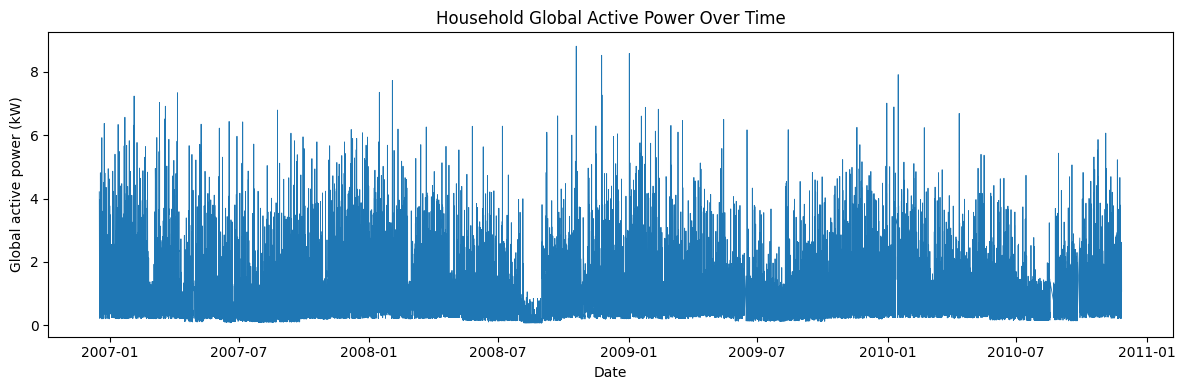

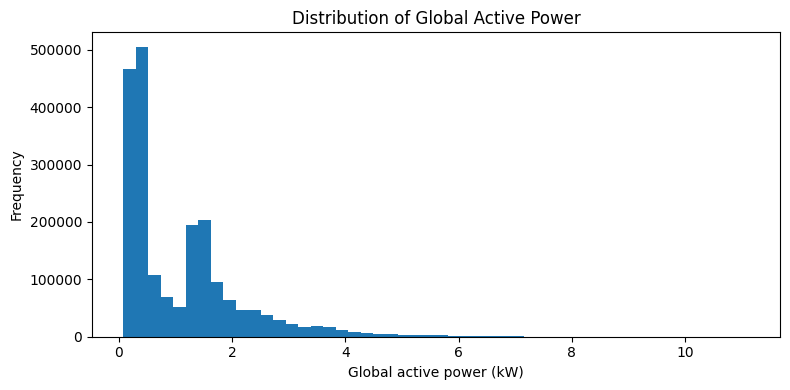

In [ ]:
display(df[numeric_cols].describe().T.round(3))

sample_step = max(1, len(df) // 20000)
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(df["Datetime"].iloc[::sample_step],
        df["Global_active_power"].iloc[::sample_step], linewidth=0.6)
ax.set(title="Household Global Active Power Over Time",
       xlabel="Date", ylabel="Global active power (kW)")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "energy_time_series.png", dpi=160)
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(df["Global_active_power"], bins=50)
ax.set(title="Distribution of Global Active Power",
       xlabel="Global active power (kW)", ylabel="Frequency")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "energy_distribution.png", dpi=160)
plt.show()

## 5. Chronological split and state discretisation

The earliest 80% of records are training data; the latest 20% are held out for testing. Quantile thresholds are learned only from training power values. Five states are used: Very Low, Low, Medium, High, and Very High.

Training records: 1,639,424 (80.0%)
Test records:     409,856 (20.0%)
Training-derived thresholds (kW): [0.272 0.4   1.266 1.742]


,State,Training count,Test count
0,Very Low,324442,63982
1,Low,329826,84840
2,Medium,328601,106047
3,High,328271,89978
4,Very High,328284,65009


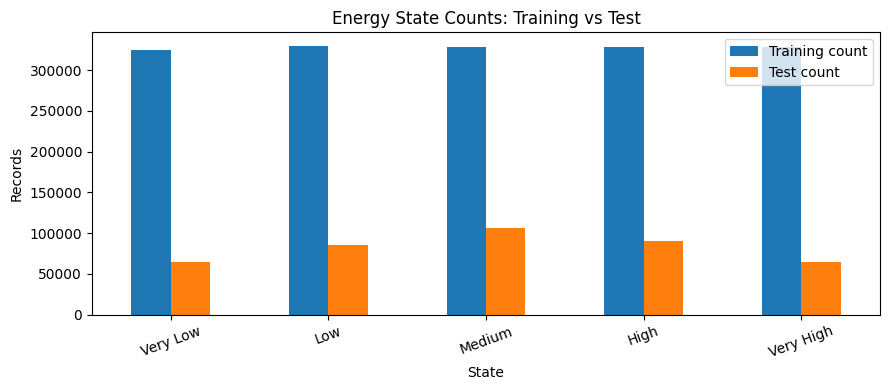

In [ ]:
split_idx = int(0.80 * len(df))
train_power = df["Global_active_power"].iloc[:split_idx].to_numpy(dtype=float)
test_power = df["Global_active_power"].iloc[split_idx:].to_numpy(dtype=float)
test_datetimes = df["Datetime"].iloc[split_idx:].reset_index(drop=True)

STATE_NAMES = ["Very Low", "Low", "Medium", "High", "Very High"]
ACTION_NAMES = ["Reduce Consumption", "Maintain Consumption", "Allow Higher Consumption"]
N_STATES, N_ACTIONS = len(STATE_NAMES), len(ACTION_NAMES)

state_edges = np.quantile(train_power, [0.2, 0.4, 0.6, 0.8])
train_states = np.digitize(train_power, state_edges).astype(np.int64)
test_states = np.digitize(test_power, state_edges).astype(np.int64)

print(f"Training records: {len(train_states):,} ({len(train_states)/len(df):.1%})")
print(f"Test records:     {len(test_states):,} ({len(test_states)/len(df):.1%})")
print("Training-derived thresholds (kW):", np.round(state_edges, 3))

state_distribution = pd.DataFrame({
    "State": STATE_NAMES,
    "Training count": np.bincount(train_states, minlength=N_STATES),
    "Test count": np.bincount(test_states, minlength=N_STATES)
})
display(state_distribution)

ax = state_distribution.set_index("State")[["Training count", "Test count"]].plot(
    kind="bar", figsize=(9, 4)
)
ax.set(title="Energy State Counts: Training vs Test", ylabel="Records")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "state_distribution.png", dpi=160)
plt.show()

## 6. Replay environment and explicit reward function

**State:** current consumption category.  
**Action:** reduce, maintain, or allow higher consumption.  
**Transition:** next recorded category in the time series.  
**Reward:** manually assigned score based on current state, next observed state, and action. Reward units are arbitrary and are not kWh, currency, or measured savings.

In [ ]:
class EnergyReplayEnvironment:
    def __init__(self, states, max_steps=MAX_STEPS):
        self.states = np.asarray(states, dtype=np.int64)
        if self.states.ndim != 1 or len(self.states) < 2:
            raise ValueError("states must be a 1-D array with at least two elements")
        if np.any((self.states < 0) | (self.states >= N_STATES)):
            raise ValueError("State IDs must be in the range 0..4")
        if max_steps < 1:
            raise ValueError("max_steps must be positive")
        self.n_states = N_STATES
        self.n_actions = N_ACTIONS
        self.max_steps = min(int(max_steps), len(self.states) - 1)
        self.current_index = 0
        self.steps = 0

    def reset(self, rng, start_index=None):
        max_start = len(self.states) - self.max_steps - 1
        if max_start < 0:
            raise ValueError("State sequence is too short for an episode")
        if start_index is None:
            self.current_index = int(rng.integers(0, max_start + 1))
        else:
            self.current_index = int(start_index)
            if not 0 <= self.current_index <= max_start:
                raise ValueError(f"start_index must be between 0 and {max_start}")
        self.steps = 0
        return int(self.states[self.current_index])

    @staticmethod
    def reward_for(state, next_state, action):
        # Transparent rule-based scores; not physical energy measurements.
        if action == 0:  # Reduce consumption
            return float((2 if state >= 2 else 0) +
                         (1 if next_state < state else (-1 if next_state > state else 0)))
        if action == 1:  # Maintain consumption
            return float((1 if state <= 2 else -1) +
                         (0.5 if abs(next_state - state) <= 1 else 0))
        if action == 2:  # Allow higher consumption
            return float((-2 if state >= 2 else 0) +
                         (-1 if next_state > state else 0))
        raise ValueError("Action must be 0, 1, or 2")

    def step(self, action):
        action = int(action)
        if not 0 <= action < self.n_actions:
            raise ValueError("Invalid action")
        state = int(self.states[self.current_index])
        self.current_index += 1
        next_state = int(self.states[self.current_index])
        reward = self.reward_for(state, next_state, action)
        self.steps += 1
        done = (self.steps >= self.max_steps or
                self.current_index >= len(self.states) - 1)
        return next_state, reward, done

train_env = EnergyReplayEnvironment(train_states)
print(f"Environment ready: {N_STATES} states, {N_ACTIONS} actions, {train_env.max_steps} steps/episode")

Environment ready: 5 states, 3 actions, 200 steps/episode


## 7. Action selection and training helpers

In [ ]:
def choose_action(q_table, state, epsilon, rng):
    if rng.random() < epsilon:
        return int(rng.integers(q_table.shape[1]))
    # Random tie-breaking during training reduces first-action bias at equal values.
    best_actions = np.flatnonzero(np.isclose(q_table[state], np.max(q_table[state])))
    return int(rng.choice(best_actions))

def moving_average(values, window=25):
    return pd.Series(values).rolling(window=window, min_periods=1).mean().to_numpy()

## 8. Q-Learning

In [ ]:
def train_q_learning(env, episodes=N_EPISODES, alpha=ALPHA, gamma=GAMMA,
                     epsilon_start=EPSILON_START, epsilon_min=EPSILON_MIN,
                     epsilon_decay=EPSILON_DECAY, seed=SEED):
    rng = np.random.default_rng(seed)  # Controls starts and actions
    q = np.zeros((env.n_states, env.n_actions), dtype=float)
    episode_rewards, episode_lengths = [], []
    epsilon = epsilon_start

    for _ in range(episodes):
        state = env.reset(rng)
        total_reward, steps = 0.0, 0
        while True:
            action = choose_action(q, state, epsilon, rng)
            next_state, reward, done = env.step(action)
            # Off-policy target: maximum next-state action value.
            target = reward if done else reward + gamma * np.max(q[next_state])
            q[state, action] += alpha * (target - q[state, action])
            state = next_state
            total_reward += reward
            steps += 1
            if done:
                break
        episode_rewards.append(total_reward)
        episode_lengths.append(steps)
        epsilon = max(epsilon_min, epsilon * epsilon_decay)

    return q, np.asarray(episode_rewards), np.asarray(episode_lengths)

start = time.perf_counter()
q_table, q_rewards, q_lengths = train_q_learning(train_env, seed=SEED)
q_training_time = time.perf_counter() - start
print(f"Q-Learning training time: {q_training_time:.3f} seconds")
display(pd.DataFrame(q_table, index=STATE_NAMES, columns=ACTION_NAMES).round(3))

Q-Learning training time: 3.897 seconds


,Reduce Consumption,Maintain Consumption,Allow Higher Consumption
Very Low,25.904,28.719,25.627
Low,25.349,27.147,26.995
Medium,34.458,34.328,31.018
High,37.506,33.565,31.834
Very High,32.004,33.141,32.478


## 9. SARSA

In [ ]:
def train_sarsa(env, episodes=N_EPISODES, alpha=ALPHA, gamma=GAMMA,
                epsilon_start=EPSILON_START, epsilon_min=EPSILON_MIN,
                epsilon_decay=EPSILON_DECAY, seed=SEED):
    rng = np.random.default_rng(seed)  # Controls starts and actions
    q = np.zeros((env.n_states, env.n_actions), dtype=float)
    episode_rewards, episode_lengths = [], []
    epsilon = epsilon_start

    for _ in range(episodes):
        state = env.reset(rng)
        action = choose_action(q, state, epsilon, rng)
        total_reward, steps = 0.0, 0
        while True:
            next_state, reward, done = env.step(action)
            if done:
                target, next_action = reward, None
            else:
                next_action = choose_action(q, next_state, epsilon, rng)
                # On-policy target: value of the next action actually selected.
                target = reward + gamma * q[next_state, next_action]
            q[state, action] += alpha * (target - q[state, action])
            total_reward += reward
            steps += 1
            if done:
                break
            state, action = next_state, next_action

        episode_rewards.append(total_reward)
        episode_lengths.append(steps)
        epsilon = max(epsilon_min, epsilon * epsilon_decay)

    return q, np.asarray(episode_rewards), np.asarray(episode_lengths)

start = time.perf_counter()
sarsa_table, sarsa_rewards, sarsa_lengths = train_sarsa(train_env, seed=SEED)
sarsa_training_time = time.perf_counter() - start
print(f"SARSA training time: {sarsa_training_time:.3f} seconds")
display(pd.DataFrame(sarsa_table, index=STATE_NAMES, columns=ACTION_NAMES).round(3))

SARSA training time: 3.487 seconds


,Reduce Consumption,Maintain Consumption,Allow Higher Consumption
Very Low,23.544,25.566,23.339
Low,22.704,24.624,24.367
Medium,31.647,30.344,27.279
High,33.050,29.506,27.805
Very High,27.769,28.876,27.887


## 10. Training reward curves

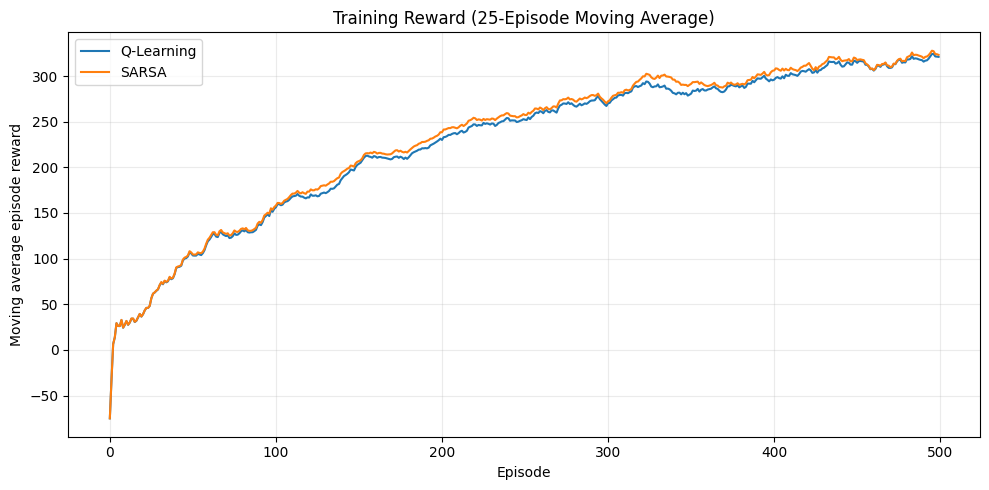

Q-Learning last-50 training reward: 318.520
SARSA last-50 training reward:      319.890


In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(moving_average(q_rewards), label="Q-Learning")
ax.plot(moving_average(sarsa_rewards), label="SARSA")
ax.set(title="Training Reward (25-Episode Moving Average)",
       xlabel="Episode", ylabel="Moving average episode reward")
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "training_reward_comparison.png", dpi=160)
plt.show()

print(f"Q-Learning last-50 training reward: {q_rewards[-50:].mean():.3f}")
print(f"SARSA last-50 training reward:      {sarsa_rewards[-50:].mean():.3f}")

## 11. Held-out chronological evaluation

The held-out test period is divided into fixed, non-overlapping windows, spread in chronological order. Both algorithms use the exact same windows. Policies are greedy during evaluation; no exploratory actions are used. This design avoids repeatedly counting overlapping test records as if they were independent episodes.

In [ ]:
def make_test_windows(states, n_windows=N_EVAL_WINDOWS, window_size=MAX_STEPS):
    states = np.asarray(states)
    if len(states) < window_size + 1:
        raise ValueError("Test period is too short for the requested evaluation window.")
    # Partition the test timeline into chronological, non-overlapping windows.
    max_windows = (len(states) - 1) // window_size
    count = min(int(n_windows), max_windows)
    if count < 1:
        raise ValueError("No complete evaluation windows available.")
    starts = np.linspace(0, (max_windows - count) * window_size,
                         num=count, dtype=int)
    starts = np.unique(starts)
    return [(int(s), int(min(window_size, len(states) - s - 1))) for s in starts]

def evaluate_policy(states, q_table, windows):
    rewards, lengths = [], []
    action_counts = np.zeros(N_ACTIONS, dtype=int)
    state_action_counts = np.zeros((N_STATES, N_ACTIONS), dtype=int)

    for start_index, length in windows:
        env = EnergyReplayEnvironment(states, max_steps=length)
        # A dedicated generator is passed only for API consistency; start is fixed.
        eval_rng = np.random.default_rng(0)
        state = env.reset(eval_rng, start_index=start_index)
        total_reward, steps = 0.0, 0
        while True:
            action = int(np.argmax(q_table[state]))  # deterministic greedy evaluation
            action_counts[action] += 1
            state_action_counts[state, action] += 1
            next_state, reward, done = env.step(action)
            total_reward += reward
            steps += 1
            state = next_state
            if done:
                break
        rewards.append(total_reward)
        lengths.append(steps)

    return np.asarray(rewards), np.asarray(lengths), action_counts, state_action_counts

test_windows = make_test_windows(test_states)
q_eval, q_eval_lengths, q_action_counts, q_state_action_counts = evaluate_policy(test_states, q_table, test_windows)
sarsa_eval, sarsa_eval_lengths, sarsa_action_counts, sarsa_state_action_counts = evaluate_policy(test_states, sarsa_table, test_windows)

assert np.array_equal(q_eval_lengths, sarsa_eval_lengths), "Evaluation windows differ between algorithms"
print(f"Shared test windows: {len(test_windows)}")
print(f"Steps per window: {q_eval_lengths.min()}–{q_eval_lengths.max()}")
single_run_results = pd.DataFrame({
    "Algorithm": ["Q-Learning", "SARSA"],
    "Mean last-50 training reward": [q_rewards[-50:].mean(), sarsa_rewards[-50:].mean()],
    "Mean test reward per window": [q_eval.mean(), sarsa_eval.mean()],
    "SD test reward per window": [q_eval.std(ddof=1), sarsa_eval.std(ddof=1)],
    "Training time (seconds)": [q_training_time, sarsa_training_time]
})
display(single_run_results.round(3))
display(pd.DataFrame({"Q-Learning": q_action_counts, "SARSA": sarsa_action_counts}, index=ACTION_NAMES))
print("Same greedy policy:", np.array_equal(q_table.argmax(axis=1), sarsa_table.argmax(axis=1)))
print("Same evaluation rewards:", np.allclose(q_eval, sarsa_eval))

Shared test windows: 100
Steps per window: 200–200


,Algorithm,Mean last-50 training reward,Mean test reward per window,SD test reward per window,Training time (seconds)
0,Q-Learning,318.52,288.92,90.1,3.897
1,SARSA,319.89,288.92,90.1,3.487


,Q-Learning,SARSA
Reduce Consumption,10278,10278
Maintain Consumption,9722,9722
Allow Higher Consumption,0,0


Same greedy policy: True
Same evaluation rewards: True


## 12. Learned policies and Q-table heatmaps

,Energy state,Q-Learning action,SARSA action,Same action
0,Very Low,Maintain Consumption,Maintain Consumption,True
1,Low,Maintain Consumption,Maintain Consumption,True
2,Medium,Reduce Consumption,Reduce Consumption,True
3,High,Reduce Consumption,Reduce Consumption,True
4,Very High,Maintain Consumption,Maintain Consumption,True


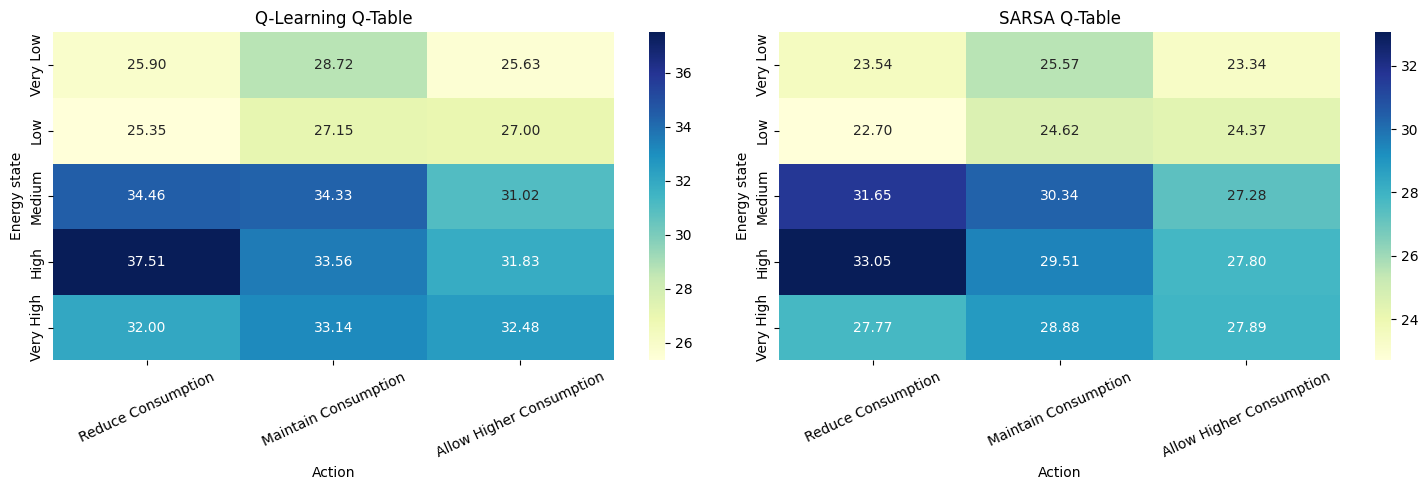

In [ ]:
policy_table = pd.DataFrame({
    "Energy state": STATE_NAMES,
    "Q-Learning action": [ACTION_NAMES[int(np.argmax(q_table[s]))] for s in range(N_STATES)],
    "SARSA action": [ACTION_NAMES[int(np.argmax(sarsa_table[s]))] for s in range(N_STATES)]
})
policy_table["Same action"] = policy_table["Q-Learning action"] == policy_table["SARSA action"]
display(policy_table)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, table, title in [
    (axes[0], q_table, "Q-Learning Q-Table"),
    (axes[1], sarsa_table, "SARSA Q-Table")
]:
    sns.heatmap(table, annot=True, fmt=".2f", cmap="YlGnBu",
                xticklabels=ACTION_NAMES, yticklabels=STATE_NAMES, ax=ax)
    ax.set(title=title, xlabel="Action", ylabel="Energy state")
    ax.tick_params(axis="x", rotation=25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "q_table_heatmaps.png", dpi=160)
plt.show()

## 13. Five-seed robustness evaluation

,Seed,Q train reward (last 50),SARSA train reward (last 50),Q mean test reward,SARSA mean test reward,Q test reward SD,SARSA test reward SD,Same greedy policy
0,0,326.03,315.06,369.965,231.615,29.115,88.676,False
1,1,314.77,314.77,325.405,369.965,88.990,29.115,False
2,2,318.05,319.44,218.665,278.350,100.449,76.900,False
3,3,319.24,323.72,312.660,369.965,77.636,29.115,False
4,4,311.88,315.07,369.965,369.965,29.115,29.115,True


,mean,std
Q train reward (last 50),317.994,5.336
SARSA train reward (last 50),317.612,3.927
Q mean test reward,319.332,61.933
SARSA mean test reward,323.972,65.110


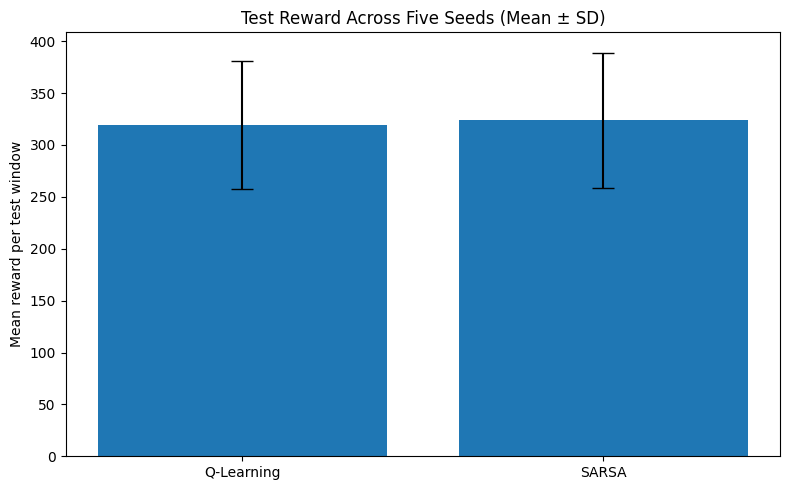

In [ ]:
robustness_rows = []
for seed in SEEDS:
    q_seed, qr_seed, _ = train_q_learning(train_env, seed=seed)
    s_seed, sr_seed, _ = train_sarsa(train_env, seed=seed)
    q_test_seed, _, _, _ = evaluate_policy(test_states, q_seed, test_windows)
    s_test_seed, _, _, _ = evaluate_policy(test_states, s_seed, test_windows)

    robustness_rows.append({
        "Seed": seed,
        "Q train reward (last 50)": qr_seed[-50:].mean(),
        "SARSA train reward (last 50)": sr_seed[-50:].mean(),
        "Q mean test reward": q_test_seed.mean(),
        "SARSA mean test reward": s_test_seed.mean(),
        "Q test reward SD": q_test_seed.std(ddof=1),
        "SARSA test reward SD": s_test_seed.std(ddof=1),
        "Same greedy policy": np.array_equal(q_seed.argmax(axis=1), s_seed.argmax(axis=1))
    })

robustness = pd.DataFrame(robustness_rows)
display(robustness.round(3))

summary_metrics = [
    "Q train reward (last 50)", "SARSA train reward (last 50)",
    "Q mean test reward", "SARSA mean test reward"
]
robustness_summary = robustness[summary_metrics].agg(["mean", "std"]).T
display(robustness_summary.round(3))

fig, ax = plt.subplots(figsize=(8, 5))
means = [robustness["Q mean test reward"].mean(), robustness["SARSA mean test reward"].mean()]
stds = [robustness["Q mean test reward"].std(ddof=1), robustness["SARSA mean test reward"].std(ddof=1)]
ax.bar(["Q-Learning", "SARSA"], means, yerr=stds, capsize=8)
ax.set(title="Test Reward Across Five Seeds (Mean ± SD)", ylabel="Mean reward per test window")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "multi_seed_test_comparison.png", dpi=160)
plt.show()

## 14. Final comparison and data-driven interpretation

,Algorithm,Mean last-50 training reward (single run),Mean test reward (single run),SD test reward (single run),"Training time (seconds, single run)",Mean test reward across seeds,SD of seed-level test means
0,Q-Learning,318.52,288.92,90.1,3.897,319.332,61.933
1,SARSA,319.89,288.92,90.1,3.487,323.972,65.110


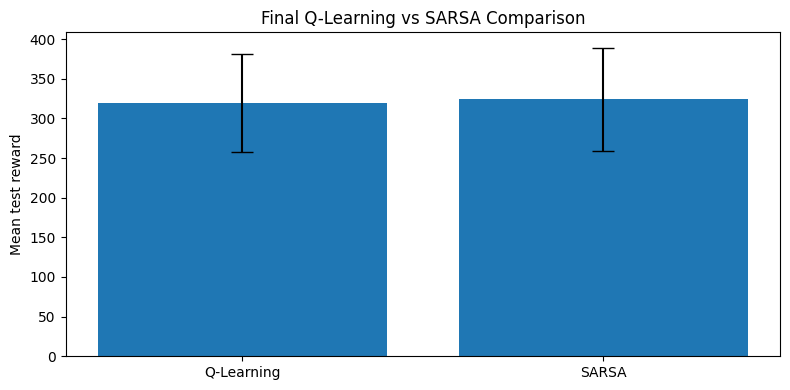

SARSA minus Q-Learning mean test reward: 4.640
Interpretation: compare the mean and variability together; five seeds provide limited evidence.
Reward is an arbitrary score under the defined rules, not measured kWh or cost saved.


In [ ]:
final_comparison = pd.DataFrame({
    "Algorithm": ["Q-Learning", "SARSA"],
    "Mean last-50 training reward (single run)": [q_rewards[-50:].mean(), sarsa_rewards[-50:].mean()],
    "Mean test reward (single run)": [q_eval.mean(), sarsa_eval.mean()],
    "SD test reward (single run)": [q_eval.std(ddof=1), sarsa_eval.std(ddof=1)],
    "Training time (seconds, single run)": [q_training_time, sarsa_training_time],
    "Mean test reward across seeds": [
        robustness["Q mean test reward"].mean(),
        robustness["SARSA mean test reward"].mean()
    ],
    "SD of seed-level test means": [
        robustness["Q mean test reward"].std(ddof=1),
        robustness["SARSA mean test reward"].std(ddof=1)
    ]
})
display(final_comparison.round(3))

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(final_comparison["Algorithm"], final_comparison["Mean test reward across seeds"],
       yerr=final_comparison["SD of seed-level test means"], capsize=8)
ax.set(title="Final Q-Learning vs SARSA Comparison", ylabel="Mean test reward")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "final_comparison.png", dpi=160)
plt.show()

q_mean = final_comparison.loc[0, "Mean test reward across seeds"]
sarsa_mean = final_comparison.loc[1, "Mean test reward across seeds"]
difference = sarsa_mean - q_mean
print(f"SARSA minus Q-Learning mean test reward: {difference:.3f}")
print("Interpretation: compare the mean and variability together; five seeds provide limited evidence.")
print("Reward is an arbitrary score under the defined rules, not measured kWh or cost saved.")

## 15. Export results

In [ ]:
final_comparison.to_csv(OUTPUT_DIR / "final_comparison.csv", index=False)
single_run_results.to_csv(OUTPUT_DIR / "single_run_results.csv", index=False)
robustness.to_csv(OUTPUT_DIR / "multi_seed_results.csv", index=False)
policy_table.to_csv(OUTPUT_DIR / "learned_policies.csv", index=False)
state_distribution.to_csv(OUTPUT_DIR / "state_distribution.csv", index=False)
pd.DataFrame(q_table, index=STATE_NAMES, columns=ACTION_NAMES).to_csv(OUTPUT_DIR / "q_learning_table.csv")
pd.DataFrame(sarsa_table, index=STATE_NAMES, columns=ACTION_NAMES).to_csv(OUTPUT_DIR / "sarsa_table.csv")
pd.DataFrame({
    "Episode": np.arange(1, N_EPISODES + 1),
    "Q-Learning reward": q_rewards,
    "SARSA reward": sarsa_rewards
}).to_csv(OUTPUT_DIR / "training_rewards.csv", index=False)

print("Exported files to:", OUTPUT_DIR.resolve())
for path in sorted(OUTPUT_DIR.iterdir()):
    print("-", path.name)

Exported files to: /content/rl_case_study_outputs
- energy_distribution.png
- energy_time_series.png
- final_comparison.csv
- final_comparison.png
- learned_policies.csv
- multi_seed_results.csv
- multi_seed_test_comparison.png
- q_learning_table.csv
- q_table_heatmaps.png
- sarsa_table.csv
- single_run_results.csv
- state_distribution.csv
- state_distribution.png
- training_reward_comparison.png
- training_rewards.csv


## 16. Conclusion, limitations, and future work

This case study compares tabular Q-Learning and SARSA using discretised household electricity-consumption records. The analysis includes chronological splitting, training-only state thresholds, seeded training, matched chronological test windows, Q-table visualisation, and a five-seed robustness check. The final conclusion must be based on the result tables generated by the current execution.

### Limitations
- The reward function is manually designed and has arbitrary units.
- Historical transitions do not respond to actions.
- Five discrete states simplify a continuous energy signal.
- The experiment does not establish actual electricity savings or deployment performance.
- Five seeds provide an initial robustness check, not a definitive statistical proof.

### Future work
- Develop and validate an action-dependent simulator or controller.
- Define rewards using explicit tariff, peak-demand, or carbon-intensity objectives.
- Evaluate on multiple households and longer chronological windows.
- Compare further algorithms only after validating the environment.

### Dataset citation
Insert the exact dataset source, author/publisher, URL, access date, and licence from the page used to download the dataset. Do not invent missing bibliographic details.